# Train/Test  vs K-Fold Cross Validation

We'll work with the Diabetes dataset:

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, cross_val_predict, train_test_split
from sklearn import datasets
from sklearn import linear_model


In [2]:
# Load the Diabetes dataset
columns = "age sex bmi map tc ldl hdl tch ltg glu".split() # Declare the columns names
diabetes = datasets.load_diabetes() # Call the diabetes dataset from sklearn
df = pd.DataFrame(diabetes.data, columns=columns) # load the dataset as a pandas data frame
y = diabetes.target # define the target variable (dependent variable) as y

A single train/test split is made easy with the predefined train_test_split function. The test_size=0.2 inside the function indicates the percentage of the data that should be held over for testing. It’s usually around 80/20 or 70/30.

In [3]:
# random_state fixé pour avoir toujours le même découpage
X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.2, random_state=0)
print (X_train.shape, y_train.shape)
print (X_test.shape, y_test.shape)

(353, 10) (353,)
(89, 10) (89,)


Now we’ll fit the model on the training data:

In [4]:
#
lm = linear_model.LinearRegression()
model = lm.fit(X_train, y_train)
predictions = lm.predict(X_test)

As you can see, we’re fitting the model on the training data and trying to predict the test data. Let’s see what (some of) the predictions are:

In [5]:
predictions[0:5]

array([238.46949509, 248.92812015, 164.05732579, 120.30774826,
       187.42483427])

Let’s plot the model:

Text(0, 0.5, 'Predictions')

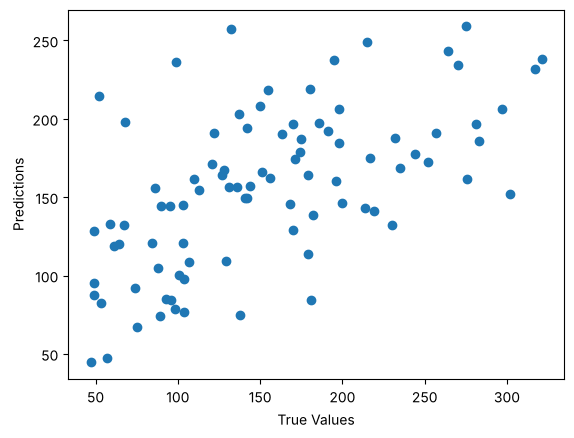

In [6]:
plt.scatter(y_test, predictions)
plt.xlabel("True Values")
plt.ylabel("Predictions")

Let's print the accuracy score:

In [7]:
print ("Score:", model.score(X_test, y_test))

Score: 0.33223321731061817


In [8]:
# Testing with other percentage splits ...
X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.3, random_state=0)
model2 = lm.fit(X_train, y_train)
predictions2 = lm.predict(X_test)
print ("Score:", model2.score(X_test, y_test)) 

Score: 0.39289927216962894


Avec un test de 20% on obtient un score (R²) de 0.33, et avec 30% on obtient 0.39. Les deux scores sont différents, donc le résultat dépend du découpage et de la taille du jeu de test. Le score est aussi assez faible (le modèle linéaire n'explique qu'un tiers à 40% de la variance), donc il y a de la marge pour améliorer.

We have loaded in the data, split it into a training and testing sets, fitted a regression model to the training data, made predictions based on this data and tested the predictions on the test data. Seems good, right? But train/test split does have its dangers — what if the split we make isn’t random? What if one subset of our data has only people from a certain state, employees with a certain income level but not other income levels, only women or only people at a certain age?. This will result in overfitting and biased results.This is where cross validation comes in.

K-Fold cross validation is just as easy; let's use a K of 5:

In [9]:
#
scores = cross_val_score(model, df, y, cv=5)
print ("Cross-validated scores for each fold :", scores)
print ("The mean accuracy of all 5 folds", scores.mean())

Cross-validated scores for each fold : [0.42955615 0.52259939 0.48268054 0.42649776 0.55024834]
The mean accuracy of all 5 folds 0.4823164359086422


Les 5 scores sont 0.43, 0.52, 0.48, 0.43 et 0.55, et la moyenne est de 0.48. Les scores varient d'un pli à l'autre (de 0.43 à 0.55), ce qui montre qu'un seul découpage peut donner un résultat trop optimiste ou trop pessimiste. La moyenne sur les 5 plis (0.48) est plus fiable que les scores obtenus avec un seul découpage (0.33 et 0.39).

- Le modèle de régression linéaire a un pouvoir explicatif moyen : environ 48% de la variance de la cible est expliquée.
- La validation croisée donne une meilleure estimation de la performance du modèle sur de nouvelles données car chaque observation est utilisée pour l'entraînement et pour le test, et on peut voir la variabilité entre les plis.
- Le train/test simple est plus rapide mais son résultat dépend beaucoup du hasard du découpage.

## Activities

<ol>
    <li> Visualize information about the Diabetes dataset using pandas </li>
    <li> Try different Train/Test split percentages and interpret the results </li>
    <li> Try changing the number of folds, what are your remarks ?</li>
    <li>Try both StratifiedKFold and LeaveOneOut from sklearn. Which one gives the best results? </li>
    <li> Instead of Linear Regression, use Polynomial Regression with different degrees. Try to obtain the best possible performance.</li>
    </ol>

In [10]:
# 1) Visualisation du dataset avec pandas
print(df.shape)
print(df.describe().round(3))
print("Valeurs manquantes :", df.isnull().sum().sum())

(442, 10)
           age      sex      bmi      map       tc      ldl      hdl      tch  \
count  442.000  442.000  442.000  442.000  442.000  442.000  442.000  442.000   
mean    -0.000    0.000   -0.000   -0.000   -0.000    0.000   -0.000   -0.000   
std      0.048    0.048    0.048    0.048    0.048    0.048    0.048    0.048   
min     -0.107   -0.045   -0.090   -0.112   -0.127   -0.116   -0.102   -0.076   
25%     -0.037   -0.045   -0.034   -0.037   -0.034   -0.030   -0.035   -0.039   
50%      0.005   -0.045   -0.007   -0.006   -0.004   -0.004   -0.007   -0.003   
75%      0.038    0.051    0.031    0.036    0.028    0.030    0.029    0.034   
max      0.111    0.051    0.171    0.132    0.154    0.199    0.181    0.185   

           ltg      glu  
count  442.000  442.000  
mean     0.000    0.000  
std      0.048    0.048  
min     -0.126   -0.138  
25%     -0.033   -0.033  
50%     -0.002   -0.001  
75%      0.032    0.028  
max      0.134    0.136  
Valeurs manquantes : 0


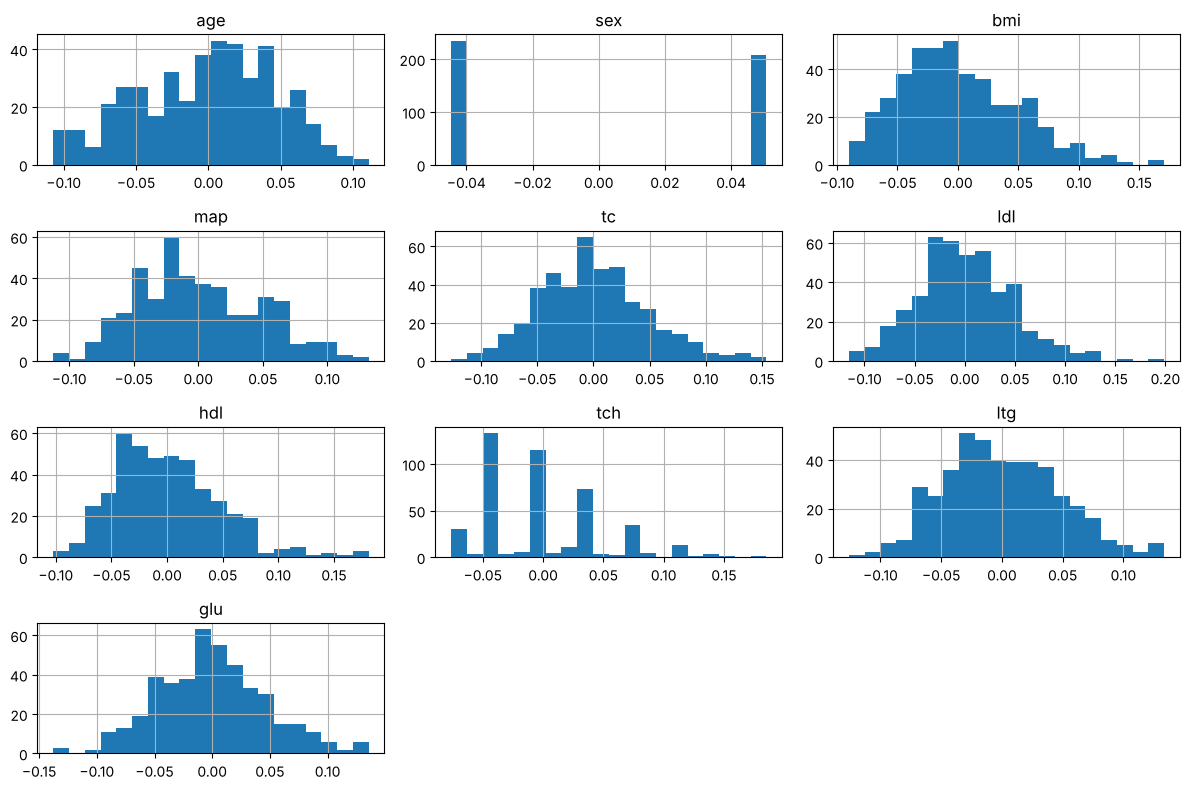

In [11]:
df.hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

target    1.000
bmi       0.586
ltg       0.566
map       0.441
tch       0.430
glu       0.382
tc        0.212
age       0.188
ldl       0.174
sex       0.043
hdl      -0.395
Name: target, dtype: float64


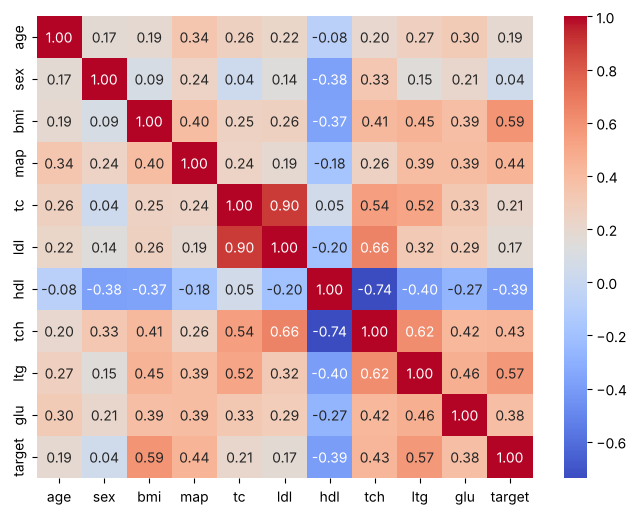

In [12]:
# corrélations entre les variables et la cible
data_all = df.copy()
data_all['target'] = y
corr = data_all.corr()
print(corr['target'].sort_values(ascending=False).round(3))

import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

In [13]:
# 2) Différents pourcentages de train/test (moyenne sur 20 découpages aléatoires)
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 0.9]:
    sc = []
    for seed in range(20):
        a, b, c, e = train_test_split(df, y, test_size=t, random_state=seed)
        sc.append(linear_model.LinearRegression().fit(a, c).score(b, e))
    print("test_size =", t, "-> score moyen =", round(np.mean(sc), 4), " écart-type =", round(np.std(sc), 4))

test_size = 0.1 -> score moyen = 0.4564  écart-type = 0.0851
test_size = 0.2 -> score moyen = 0.4646  écart-type = 0.0639
test_size = 0.3 -> score moyen = 0.4774  écart-type = 0.0452
test_size = 0.4 -> score moyen = 0.4602  écart-type = 0.045
test_size = 0.5 -> score moyen = 0.4623  écart-type = 0.0326
test_size = 0.7 -> score moyen = 0.4526  écart-type = 0.0251


test_size = 0.9 -> score moyen = 0.3531  écart-type = 0.0748


Le score moyen reste stable (entre 0.45 et 0.48) pour des tailles de test de 10% à 70%, avec un maximum de 0.477 pour 30%. Il baisse nettement à 0.35 pour 90% de test, car il ne reste que très peu de données pour entraîner le modèle. L'écart-type diminue quand le jeu de test grandit (0.085 pour 10% contre 0.025 pour 70%) : une estimation sur un petit jeu de test est plus instable. Les pourcentages classiques 70/30 ou 80/20 sont donc un bon compromis.

In [14]:
# 3) Différents nombres de plis
for k in [2, 3, 5, 10, 20, 50]:
    s = cross_val_score(linear_model.LinearRegression(), df, y, cv=k)
    print("k =", k, "-> moyenne =", round(s.mean(), 4), " écart-type =", round(s.std(), 4), " min =", round(s.min(), 4))

k = 2 -> moyenne = 0.4924  écart-type = 0.0324  min = 0.46
k = 3 -> moyenne = 0.4887  écart-type = 0.0165  min = 0.4693
k = 5 -> moyenne = 0.4823  écart-type = 0.0493  min = 0.4265
k = 10 -> moyenne = 0.462  écart-type = 0.147  min = 0.2306
k = 20 -> moyenne = 0.4093  écart-type = 0.2236  min = -0.1024
k = 50 -> moyenne = 0.3568  écart-type = 0.3444  min = -0.5577


Quand on augmente le nombre de plis, le score moyen diminue (0.49 pour k=2, 0.48 pour k=5, 0.41 pour k=20 et 0.36 pour k=50) et surtout l'écart-type augmente beaucoup (0.03 pour k=2 contre 0.34 pour k=50, avec un minimum négatif). Avec beaucoup de plis chaque pli de test contient très peu d'observations (environ 9 pour k=50), donc le R² par pli est très instable. Les valeurs k=5 ou k=10 sont un bon compromis entre biais et variance (et le temps de calcul augmente avec k).

In [15]:
# 4) StratifiedKFold et LeaveOneOut
from sklearn.model_selection import StratifiedKFold, LeaveOneOut, KFold

# StratifiedKFold a besoin de classes : y est continu, donc on le découpe en 5 tranches (quantiles)
y_classes = pd.qcut(y, 5, labels=False)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
kf = KFold(n_splits=5, shuffle=True, random_state=0)
lm = linear_model.LinearRegression()

s_kf = cross_val_score(lm, df, y, cv=kf)
s_skf = cross_val_score(lm, df, y, cv=skf.split(df, y_classes))
print("KFold            : R² moyen =", round(s_kf.mean(), 4))
print("StratifiedKFold  : R² moyen =", round(s_skf.mean(), 4))

# LeaveOneOut : avec un seul échantillon de test le R² n'est pas défini, on utilise donc l'erreur quadratique
loo = LeaveOneOut()
mse_loo = -cross_val_score(lm, df, y, cv=loo, scoring='neg_mean_squared_error').mean()
mse_kf = -cross_val_score(lm, df, y, cv=kf, scoring='neg_mean_squared_error').mean()
mse_skf = -cross_val_score(lm, df, y, cv=skf.split(df, y_classes), scoring='neg_mean_squared_error').mean()
print()
print("MSE KFold           :", round(mse_kf, 2))
print("MSE StratifiedKFold :", round(mse_skf, 2))
print("MSE LeaveOneOut     :", round(mse_loo, 2))

KFold            : R² moyen = 0.4892
StratifiedKFold  : R² moyen = 0.4919



MSE KFold           : 2977.6
MSE StratifiedKFold : 3034.82
MSE LeaveOneOut     : 3001.75


`StratifiedKFold` est fait pour des classes, donc ici il a fallu découper la variable cible en 5 tranches (quantiles) pour pouvoir l'utiliser. Les résultats sont presque identiques : R² moyen de 0.489 pour KFold et 0.492 pour StratifiedKFold. Pour LeaveOneOut le R² n'est pas défini sur un seul exemple, donc on a comparé avec le MSE : 2978 (KFold), 3035 (Stratified) et 3002 (LeaveOneOut). Les écarts sont de moins de 2%, donc aucune méthode n'est vraiment meilleure ici. LeaveOneOut demande 442 entraînements, il est donc beaucoup plus coûteux pour un résultat équivalent, et on préfère KFold avec k = 5 ou 10.

In [16]:
# 5) Régression polynomiale avec différents degrés
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

kf10 = KFold(n_splits=10, shuffle=True, random_state=0)
for d in [1, 2, 3, 4]:
    modele = make_pipeline(PolynomialFeatures(d), linear_model.LinearRegression())
    s = cross_val_score(modele, df, y, cv=kf10)
    print("degré", d, "-> R² moyen (CV 10 plis) =", round(s.mean(), 4))

degré 1 -> R² moyen (CV 10 plis) = 0.4839
degré 2 -> R² moyen (CV 10 plis) = 0.4082
degré 3 -> R² moyen (CV 10 plis) = -4.5541


degré 4 -> R² moyen (CV 10 plis) = -93.0645


In [17]:
# avec le degré 2 ou 3, il y a beaucoup de variables : on essaie d'ajouter une régularisation (Ridge)
for d in [1, 2, 3]:
    for alpha in [0.1, 1, 10, 100]:
        modele = make_pipeline(PolynomialFeatures(d), StandardScaler(), linear_model.Ridge(alpha=alpha))
        s = cross_val_score(modele, df, y, cv=kf10)
        print("degré", d, " alpha", alpha, "-> R² moyen =", round(s.mean(), 4))

degré 1  alpha 0.1 -> R² moyen = 0.4839
degré 1  alpha 1 -> R² moyen = 0.484
degré 1  alpha 10 -> R² moyen = 0.4833
degré 1  alpha 100 -> R² moyen = 0.4783
degré 2  alpha 0.1 -> R² moyen = 0.416


degré 2  alpha 1 -> R² moyen = 0.428


degré 2  alpha 10 -> R² moyen = 0.4494
degré 2  alpha 100 -> R² moyen = 0.4687
degré 3  alpha 0.1 -> R² moyen = -1.2551


degré 3  alpha 1 -> R² moyen = -0.4228


degré 3  alpha 10 -> R² moyen = 0.1601
degré 3  alpha 100 -> R² moyen = 0.4067


Avec la régression polynomiale, la performance se dégrade : R² moyen (10 plis) de 0.484 pour le degré 1, 0.408 pour le degré 2, -4.55 pour le degré 3 et -93 pour le degré 4. Le nombre de variables explose (10 variables → 65 en degré 2, 285 en degré 3) pour seulement 442 observations, donc il y a un fort surapprentissage.

La régularisation Ridge améliore beaucoup les degrés 2 et 3 (0.469 pour le degré 2 avec alpha = 100 et 0.407 pour le degré 3), mais elle ne dépasse pas le modèle linéaire (0.484 avec alpha = 1). La meilleure performance obtenue est donc d'environ **R² = 0.48** avec le modèle linéaire simple : sur ce jeu de données les relations sont surtout linéaires et un modèle plus complexe n'apporte rien.